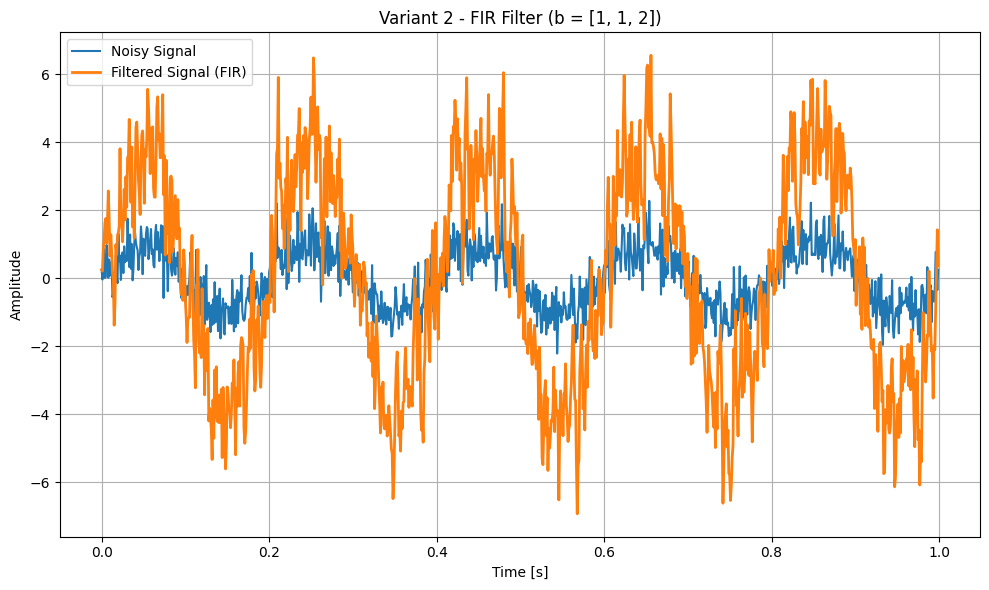

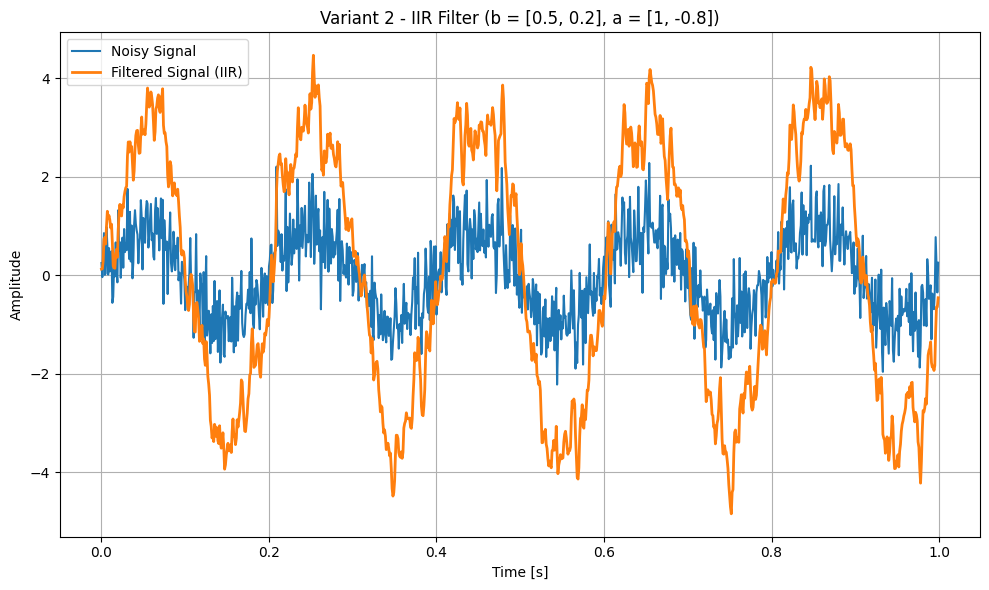

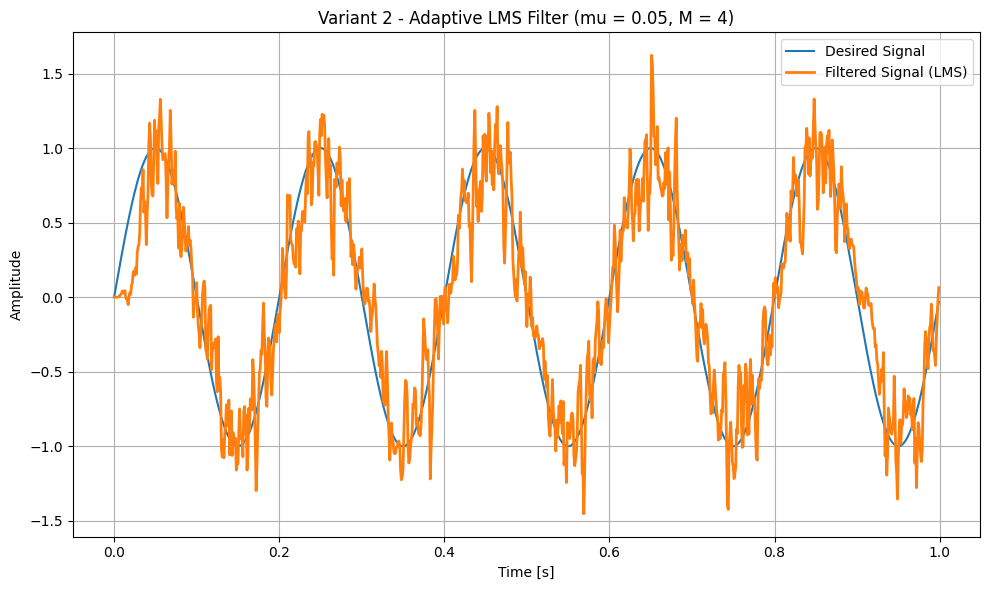

Final LMS weights: [0.11059467 0.13117327 0.14877729 0.15684842]


In [3]:
import matplotlib.pyplot as plt
import numpy as np


def fir_filter(x, b):
  """FIR filter implementation."""
  b = np.asarray(b, dtype=float)
  M = len(b)
  y = np.zeros(len(x), dtype=float)
  for n in range(len(x)):
    start = max(0, n - M + 1)
    seg = x[start : n + 1][::-1]
    y[n] = np.dot(b[: len(seg)], seg)
  return y


def iir_filter(x, b, a):
  """IIR filter implementation (Direct Form I)."""
  b = np.asarray(b, dtype=float)
  a = np.asarray(a, dtype=float)
  M = len(b)
  N = len(a)
  y = np.zeros(len(x), dtype=float)
  for n in range(len(x)):
    start_x = max(0, n - M + 1)
    seg_x = x[start_x : n + 1][::-1]
    y[n] = np.dot(b[: len(seg_x)], seg_x)
    if n > 0 and N > 1:
      start_y = max(0, n - N + 1)
      seg_y = y[start_y:n][::-1]
      y[n] -= np.dot(a[1 : 1 + len(seg_y)], seg_y)
  return y


def lms_filter(x, d, mu, num_taps):
  """LMS adaptive filter implementation."""
  n_samples = len(x)
  w = np.zeros(num_taps, dtype=float)
  y = np.zeros(n_samples, dtype=float)
  e = np.zeros(n_samples, dtype=float)
  for i in range(num_taps, n_samples):
    x_segment = x[i - num_taps : i][::-1]
    y[i] = np.dot(w, x_segment)
    e[i] = d[i] - y[i]
    w = w + mu * e[i] * x_segment
  return y, e, w


# Noisy sinusoidal signal (based on manual example)
np.random.seed(42)
fs = 1000
t = np.linspace(0, 1, fs, endpoint=False)
d = np.sin(2 * np.pi * 5 * t)  # Desired clean sinusoid
x = d + 0.5 * np.random.randn(len(t))  # Noisy input signal

# Variant 2 parameters
b_fir = [1.0, 1.0, 2.0]
b_iir = [0.5, 0.2]
a_iir = [1.0, -0.8]
mu = 0.05
M_lms = 4

y_fir = fir_filter(x, b_fir)
y_iir = iir_filter(x, b_iir, a_iir)
y_lms, e_lms, w_lms = lms_filter(x, d, mu, M_lms)

# 1. FIR plot
plt.figure(figsize=(10, 6))
plt.plot(t, x, label='Noisy Signal')
plt.plot(t, y_fir, label='Filtered Signal (FIR)', linewidth=2)
plt.legend()
plt.title('Variant 2 - FIR Filter (b = [1, 1, 2])')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid(True)
plt.tight_layout()
plt.savefig('fir_filter_variant2.png', dpi=200)
plt.show()

# 2. IIR plot
plt.figure(figsize=(10, 6))
plt.plot(t, x, label='Noisy Signal')
plt.plot(t, y_iir, label='Filtered Signal (IIR)', linewidth=2)
plt.legend()
plt.title('Variant 2 - IIR Filter (b = [0.5, 0.2], a = [1, -0.8])')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid(True)
plt.tight_layout()
plt.savefig('iir_filter_variant2.png', dpi=200)
plt.show()

# 3. LMS plot
plt.figure(figsize=(10, 6))
plt.plot(t, d, label='Desired Signal')
plt.plot(t, y_lms, label='Filtered Signal (LMS)', linewidth=2)
plt.legend()
plt.title('Variant 2 - Adaptive LMS Filter (mu = 0.05, M = 4)')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid(True)
plt.tight_layout()
plt.savefig('lms_filter_variant2.png', dpi=200)
plt.show()

print('Final LMS weights:', w_lms)